Load hết trong model_train_package_3

In [2]:
# ==========================================
# PACKAGE 4
# Explainability & Deployment
# ==========================================

import pandas as pd
import numpy as np
import joblib
import json

import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# LOAD PROCESSED DATA
# ==========================================

df = pd.read_csv(
    r"E:\Banking_AI\data\data_process\creditcard_processed.csv"
)

# ==========================================
# SPLIT FEATURE / TARGET
# ==========================================

X = df.drop("Class", axis=1)
y = df["Class"]

# ==========================================
# LOAD BEST MODEL
# ==========================================

best_xgb = joblib.load(
    r"E:\Banking_AI\data\data_process\model_train_package_3\best_xgb_tuned.pkl"
)

# ==========================================
# LOAD THRESHOLD
# ==========================================

with open(
    r"E:\Banking_AI\data\data_process\model_train_package_3\best_threshold.json",
    "r"
) as f:

    threshold_info = json.load(f)

best_threshold = threshold_info["best_threshold"]

# ==========================================
# LOAD GRID RESULTS
# ==========================================

grid_results = pd.read_csv(
    r"E:\Banking_AI\data\data_process\model_train_package_3\grid_results.csv"
)

# ==========================================
# LOAD FINAL METRICS
# ==========================================

final_results = pd.read_csv(
    r"E:\Banking_AI\data\data_process\model_train_package_3\final_results.csv"
)

# ==========================================
# CHECKPOINT
# ==========================================

print("="*50)
print("PACKAGE 4 READY")
print("="*50)

print("\nDataset:")
print(df.shape)

print("\nBest Threshold:")
print(best_threshold)

print("\nFinal Metrics:")
display(final_results)

print("\nTop Grid Results:")
display(
    grid_results.sort_values(
        "mean_test_score",
        ascending=False
    ).head()
)

PACKAGE 4 READY

Dataset:
(284807, 31)

Best Threshold:
0.95

Final Metrics:


,Model,Precision,Recall,F1,Threshold
0,XGBoost Final,0.94,0.82,0.87,0.95



Top Grid Results:


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_learning_rate,param_max_depth,param_n_estimators,params,split0_test_score,split1_test_score,split2_test_score,split3_test_score,split4_test_score,mean_test_score,std_test_score,rank_test_score
23,16.811560,0.112401,0.244720,0.026316,0.10,6,300,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",0.844156,0.859155,0.843537,0.862500,0.876712,0.857212,0.012405,1
22,11.329576,0.137220,0.236686,0.015760,0.10,6,200,"{'learning_rate': 0.1, 'max_depth': 6, 'n_esti...",0.833333,0.859155,0.843537,0.869565,0.870748,0.855268,0.014683,2
26,13.079321,0.404696,0.101505,0.033368,0.10,8,300,"{'learning_rate': 0.1, 'max_depth': 8, 'n_esti...",0.847682,0.848921,0.843537,0.850000,0.882759,0.854580,0.014259,3
25,13.142422,0.871662,0.184410,0.031367,0.10,8,200,"{'learning_rate': 0.1, 'max_depth': 8, 'n_esti...",0.855263,0.828571,0.843537,0.850000,0.882759,0.852026,0.017783,4
14,20.145758,0.143716,0.271329,0.013863,0.05,6,300,"{'learning_rate': 0.05, 'max_depth': 6, 'n_est...",0.838710,0.841379,0.845638,0.846626,0.859060,0.846283,0.007003,5


In [3]:
import shap

print(shap.__version__)


0.51.0


e:\Banking_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Section 1: Tạo SHAP Explainer

In [6]:
import shap

explainer = shap.TreeExplainer(best_xgb)

print("shap ok")

shap ok


In [7]:
shap_values = explainer.shap_values(X)

print(type(shap_values))
print(np.array(shap_values).shape)

<class 'numpy.ndarray'>
(284807, 30)


* vẽ plot shap

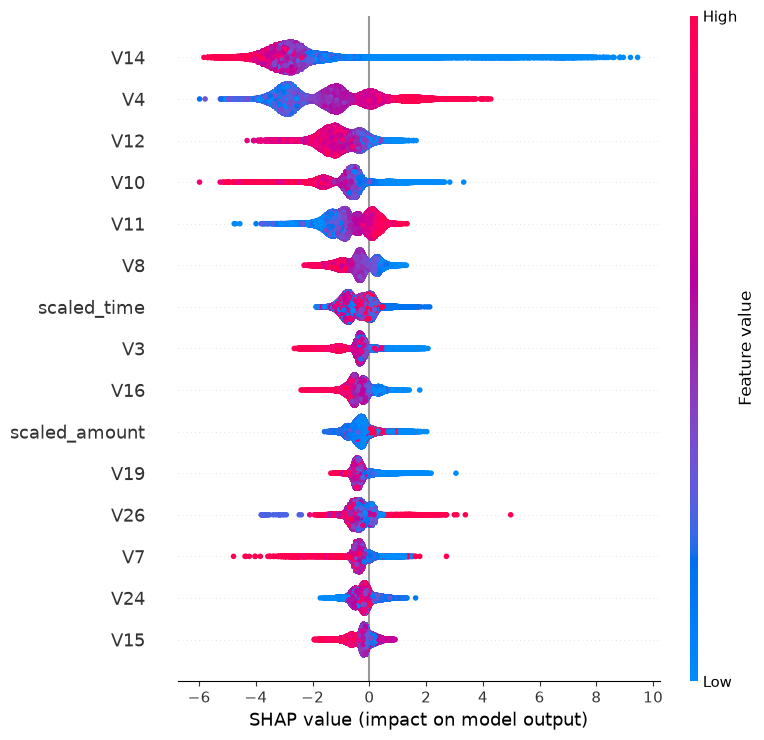

In [8]:
shap.summary_plot(
				shap_values,
    X,
    max_display=15
)


tìm 1 giao dịch Fraud thật

In [15]:
fraud_index = y[y == 1].index[10]
print(fraud_index)

6446


In [16]:
X.loc[fraud_index]

V1               0.702710
V2               2.426433
V3              -5.234513
V4               4.416661
V5              -2.170806
V6              -2.667554
V7              -3.878088
V8               0.911337
V9              -0.166199
V10             -5.009249
V11              4.675729
V12             -8.167188
V13              0.638559
V14             -6.763334
V15              1.296860
V16             -3.811758
V17             -3.754128
V18             -1.049177
V19              1.554197
V20              0.422743
V21              0.551180
V22             -0.009802
V23              0.721698
V24              0.473246
V25             -1.959304
V26              0.319476
V27              0.600485
V28              0.129305
scaled_amount   -0.349231
scaled_time     -1.835027
Name: 6446, dtype: float64

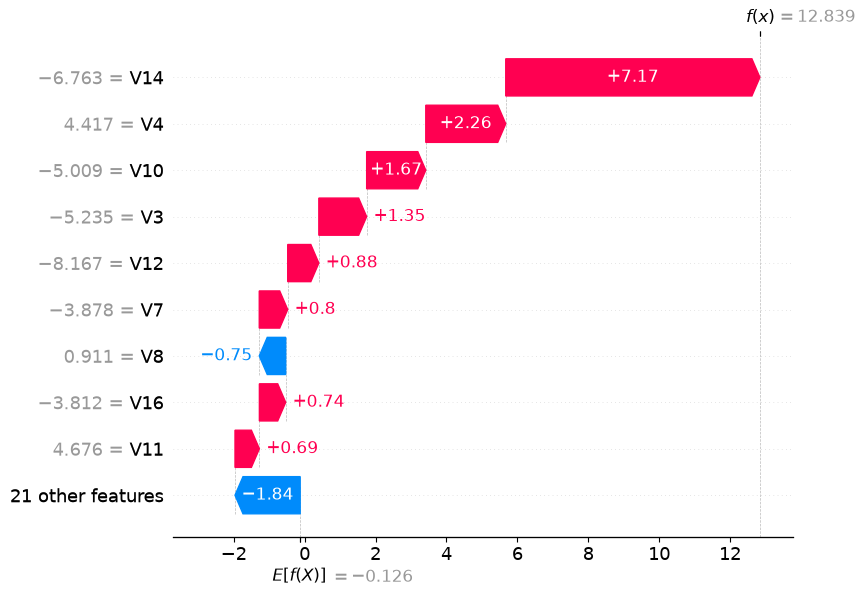

In [18]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[fraud_index],
        base_values=explainer.expected_value,
        data=X.loc[fraud_index],
        feature_names=X.columns
    )
)

Section 3: Dependence Plot

lọc feature mạnh nhất, khảo sát trong đây cho thấy v14 có sức ảnh hưởng cao nhất, sau đó là v4 rồi so sánh

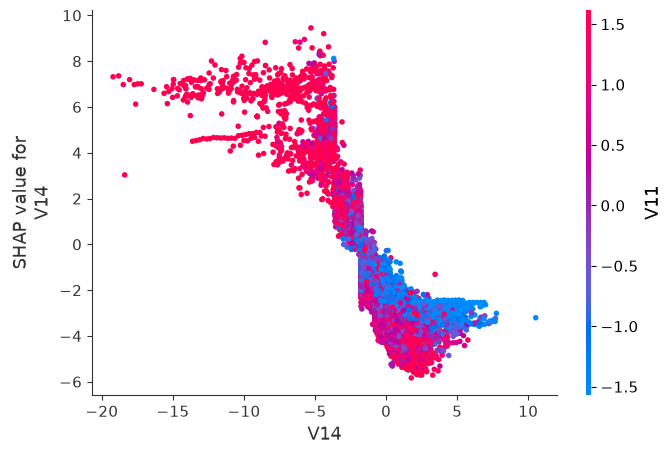

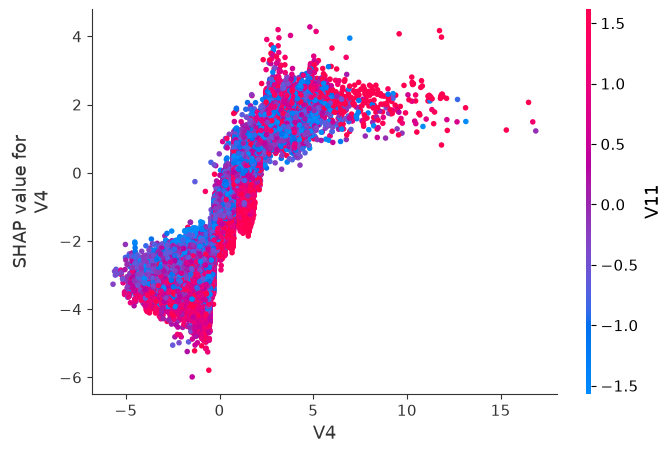

In [23]:
shap.dependence_plot(
    "V14",
    shap_values,
    X
)
shap.dependence_plot(
    "V4",
    shap_values,
    X
)

✅ Summary Plot
Feature nào quan trọng nhất

✅ Waterfall Plot
Tại sao giao dịch 6446 là Fraud

✅ Dependence Plot V14
V14 thấp → Fraud mạnh

✅ Dependence Plot V4
V4 cao → Fraud hơn nhưng yếu hơn V14

✅ Decision Plot
Quan sát đường suy luận của model

Section 5: Decision Plot

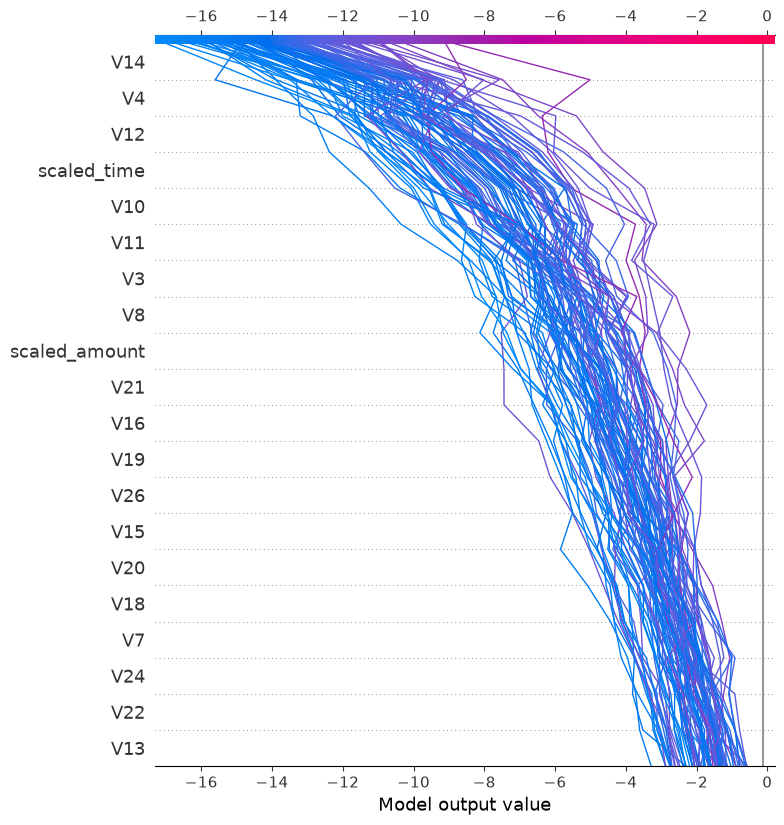

In [21]:
shap.decision_plot(
    explainer.expected_value,
    shap_values[:100],
    X.iloc[:100]
)